# GA1 Model 2 — Use predictors with missing values

Model 1 excluded every predictor containing a missing value. Model 2 tests whether carefully processed missing-value predictors improve training-only 5-fold ROC-AUC. It uses the same target definition, seed, 70/30 split, and Model 1 baseline. The reserved test set is not evaluated in this notebook.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

input_path = Path("COVID-19BehaviorData_CAN2022.csv")
if not input_path.exists():
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            f"Put {input_path.name} in the same folder as this notebook, then run again."
        ) from exc
    print(f"Upload {input_path.name} to the Colab runtime.")
    uploaded = files.upload()
    if input_path.name not in uploaded:
        raise FileNotFoundError(f"Upload the file named {input_path.name} to continue.")

data = pd.read_csv(input_path, low_memory=False)
print(f"Original shape: {data.shape[0]:,} rows × {data.shape[1]:,} columns")

Original shape: 6,430 rows × 512 columns


## 1. Reproduce cleaning and target definition

Convert whitespace and `__NA__` to missing values, remove columns that are empty for all respondents, and define `vac_boost_1`. The 644 skipped booster responses all belong to respondents with neither first nor second dose, so they are inferred as `No`, matching Model 1.

In [2]:
text_columns = data.select_dtypes(include=["object", "string"]).columns
data[text_columns] = data[text_columns].replace(r"^\s*$", pd.NA, regex=True)
data[text_columns] = data[text_columns].replace("__NA__", pd.NA)
cleaned_data = data.dropna(axis=1, how="all").copy()

original_booster_response = cleaned_data["vac_boost_1"].copy()
skipped_target = original_booster_response.isna()
assert skipped_target.sum() == 644
assert (cleaned_data.loc[skipped_target, "vac"] == "No, neither").all()
cleaned_data["vac_boost_1"] = original_booster_response.fillna("No")
cleaned_data = cleaned_data.where(cleaned_data.notna(), np.nan)
print(f"Nonempty-column shape: {cleaned_data.shape[0]:,} × {cleaned_data.shape[1]:,}")
print(cleaned_data["vac_boost_1"].value_counts().to_string())

Nonempty-column shape: 6,430 × 159
vac_boost_1
Yes    3646
No     2784


## 2. Reconcile the 101 versus 85 missing-column counts

After restoring all 6,430 respondents, 101 columns contain missing values. Sixteen of them have no observations among respondents who directly answered the booster question; they are reasons asked only of people with neither first nor second dose. These columns are structurally tied to the target construction and are excluded. The remaining count is exactly 85.

In [3]:
columns_with_missing = [name for name in cleaned_data if cleaned_data[name].isna().any()]
direct_booster_answer = original_booster_response.notna()
never_vaccinated_branch = [
    name for name in columns_with_missing
    if cleaned_data.loc[direct_booster_answer, name].notna().sum() == 0
]
missing_85 = [name for name in columns_with_missing if name not in never_vaccinated_branch]

print(f"Columns with missing values: {len(columns_with_missing)}")
print(f"Excluded never-vaccinated branch: {len(never_vaccinated_branch)}")
print(f"Model 2 missing-column pool: {len(missing_85)}")
assert len(columns_with_missing) == 101
assert len(never_vaccinated_branch) == 16
assert len(missing_85) == 85
print("\nExcluded 16 columns:")
print(never_vaccinated_branch)

Columns with missing values: 101
Excluded never-vaccinated branch: 16
Model 2 missing-column pool: 85

Excluded 16 columns:
['vac_1', 'vac12_1', 'vac12_2', 'vac12_3', 'vac12_4', 'vac12_11', 'vac12_5', 'vac12_6', 'vac12_7', 'vac12_8', 'vac12_9', 'vac12_10', 'vac12_96', 'vac12_other', 'vac12_12', 'vac12_13']


           variable  missing_n  missing_pct  observed_levels
          Soc2_open       6297         97.9              103
            q_other       6191         96.3              206
vac12_booster_other       6046         94.0              370
   i14_health_other       5929         92.2              358
         long_covid       5635         87.6                5
              WAH_2       5493         85.4                5
              WAH_1       5493         85.4                5
              WAH_3       5493         85.4                5
             Soc2_1       5469         85.1                2
             Soc2_2       5469         85.1                2
             Soc2_3       5469         85.1                2
             Soc2_4       5469         85.1                2
             Soc2_5       5469         85.1                2
             Soc2_6       5469         85.1                2
          had_covid       5459         84.9                2
           future_3     

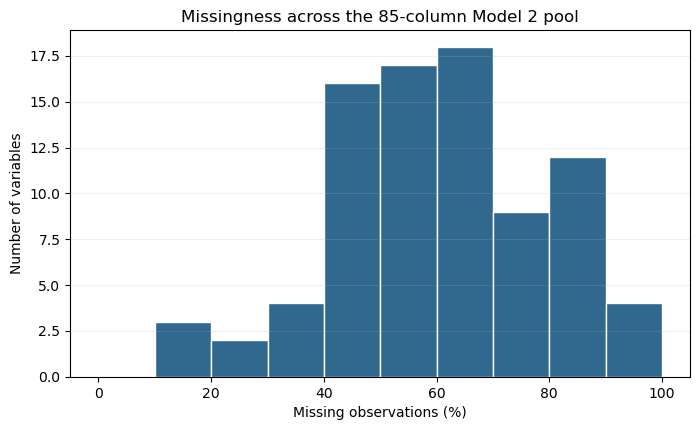

In [4]:
missing_summary = pd.DataFrame({
    "variable": missing_85,
    "missing_n": [cleaned_data[name].isna().sum() for name in missing_85],
    "missing_pct": [cleaned_data[name].isna().mean() * 100 for name in missing_85],
    "observed_levels": [cleaned_data[name].nunique(dropna=True) for name in missing_85],
}).sort_values("missing_pct", ascending=False)
print(missing_summary.round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(missing_summary["missing_pct"], bins=np.arange(0, 105, 10), color="#31688e", edgecolor="white")
ax.set(title="Missingness across the 85-column Model 2 pool", xlabel="Missing observations (%)", ylabel="Number of variables")
ax.grid(axis="y", alpha=0.2)
plt.show()

## 3. Remove target leakage and free-text fields

Booster follow-up questions are asked conditionally based on booster status, so their presence or absence reveals the target. Free-text responses have very high cardinality and cannot be meaningfully represented as ordinary categories for k-NN. Both groups are documented and excluded before screening.

In [5]:
booster_followup_columns = [
    name for name in missing_85
    if ("boost" in name.lower() and name != "vac_boost_1")
]
free_text_columns = [
    name for name in ["i14_health_other", "Soc2_open", "q_other"]
    if name in missing_85
]
excluded_model2_columns = sorted(set(booster_followup_columns + free_text_columns))
eligible_missing_predictors = [
    name for name in missing_85 if name not in excluded_model2_columns
]

print(f"Booster follow-up leakage columns excluded: {len(booster_followup_columns)}")
print(booster_followup_columns)
print(f"\nFree-text columns excluded: {len(free_text_columns)}")
print(free_text_columns)
print(f"\nEligible missing-value predictors: {len(eligible_missing_predictors)}")

Booster follow-up leakage columns excluded: 14
['vac_boost_2', 'vac12_booster_1', 'vac12_booster_2', 'vac12_booster_3', 'vac12_booster_4', 'vac12_booster_5', 'vac12_booster_6', 'vac12_booster_7', 'vac12_booster_8', 'vac12_booster_9', 'vac12_booster_10', 'vac12_booster_96', 'vac12_booster_other', 'vac_boost_beyond']

Free-text columns excluded: 3
['i14_health_other', 'Soc2_open', 'q_other']

Eligible missing-value predictors: 68


## 4. Create the same seeded train/test split

Use `SEED = 20261110`, matching the final Model 1 development split. Model 2 screening and tuning use only the 70% training portion. The test portion remains unscored.

In [6]:
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 20261110
train_data, test_data = train_test_split(
    cleaned_data,
    test_size=0.30,
    random_state=SEED,
    stratify=cleaned_data["vac_boost_1"],
)
validation_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
y_train = train_data["vac_boost_1"].eq("Yes").astype(int)
print(f"Training set: {len(train_data):,} rows")
print(f"Reserved test set: {len(test_data):,} rows — not scored")

Training set: 4,501 rows
Reserved test set: 1,929 rows — not scored


## 5. Training-only screening of missing-value predictors

Process every eligible missing-value predictor inside the modeling pipeline. Treat `i2_health` as numeric: median-impute it, add a missingness indicator, and standardize it. Treat all other fields as categorical: replace missing values with the explicit category `Not asked / missing`, then one-hot encode. L1 logistic regression is used only to screen variables on training folds; it is not Model 2's final algorithm.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegressionCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

screening_data = train_data[eligible_missing_predictors].copy()
screening_data["i2_health"] = pd.to_numeric(screening_data["i2_health"], errors="coerce")
numeric_missing = ["i2_health"]
categorical_missing = [name for name in eligible_missing_predictors if name not in numeric_missing]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Not asked / missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
screening_preprocess = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_missing),
    ("categorical", categorical_pipeline, categorical_missing),
])
missing_selector = Pipeline([
    ("preprocess", screening_preprocess),
    ("logistic", LogisticRegressionCV(
        Cs=[0.01, 0.03, 0.1, 0.3, 1.0],
        cv=validation_cv,
        penalty="l1",
        solver="liblinear",
        scoring="roc_auc",
        max_iter=3000,
        random_state=SEED,
        n_jobs=1,
        refit=True,
    )),
])
missing_selector.fit(screening_data, y_train)
selector_model = missing_selector.named_steps["logistic"]
print(f"Screened missing-value predictors: {len(eligible_missing_predictors)}")
print(f"Selected C: {selector_model.C_[0]}")
print(f"Best mean training-fold AUC: {selector_model.scores_[1].mean(axis=0).max():.4f}")

Screened missing-value predictors: 68
Selected C: 0.3
Best mean training-fold AUC: 0.7408


In [8]:
encoded_names = missing_selector.named_steps["preprocess"].get_feature_names_out()
coefficients = selector_model.coef_[0]
importance_rows = []
for variable in eligible_missing_predictors:
    if variable == "i2_health":
        match = np.array([
            ("i2_health" in name) for name in encoded_names
        ])
    else:
        match = np.array([
            name.startswith(f"categorical__{variable}_") for name in encoded_names
        ])
    variable_coefficients = np.abs(coefficients[match])
    importance_rows.append({
        "variable": variable,
        "max_abs_coefficient": variable_coefficients.max() if len(variable_coefficients) else 0.0,
        "nonzero_terms": int((variable_coefficients > 1e-8).sum()),
        "missing_pct": cleaned_data[variable].isna().mean() * 100,
    })
missing_importance = pd.DataFrame(importance_rows).sort_values(
    ["max_abs_coefficient", "nonzero_terms"], ascending=False
)
retained_missing = missing_importance.query("nonzero_terms > 0").copy()
print(f"Missing-value variables with at least one nonzero term: {len(retained_missing)}")
print(retained_missing.head(25).round(4).to_string(index=False))

Missing-value variables with at least one nonzero term: 53
     variable  max_abs_coefficient  nonzero_terms  missing_pct
    travel1_4               0.8747              1      74.6345
  d1_health_8               0.6693              2      47.0918
i12_health_10               0.6391              5      68.3981
     future_1               0.5680              3      25.3655
i12_health_23               0.5488              3      15.5677
    had_covid               0.5413              2      84.8989
  had_covid_2               0.5413              1      44.4790
 i12_health_9               0.5244              3      55.9876
           w2               0.5168              3      74.6345
i12_health_11               0.5065              5      15.5677
 i14_health_7               0.5059              2      55.9876
 i12_health_2               0.4467              4      15.5677
i12_health_24               0.4203              4      55.9876
  d1_health_5               0.4170              2      47.0

## 6. Build and cross-validate Model 2

Add the 15 highest-ranked missing-value predictors to Model 1's locked 14 predictors. This gives Model 2 a controlled opportunity to benefit from missing-value information without allowing all conditional survey branches to dominate k-NN distance. Tune Model 2 only on training folds and compare it with the locked Model 1 training-CV result.

In [9]:
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.neighbors import KNeighborsClassifier

model1_features = [
    "qweek", "vac7", "age", "vac_man_7", "r1_2", "cantril_ladder",
    "i12_health_8", "employment_status", "vac2_7", "i12_health_7",
    "vac2_1", "vac_man_3", "vac2_2", "r1_8",
]
added_missing_features = retained_missing.head(15)["variable"].tolist()
model2_features = model1_features + [
    name for name in added_missing_features if name not in model1_features
]
print(f"Model 1 variables: {len(model1_features)}")
print(f"Added missing-value variables: {len(added_missing_features)}")
print(added_missing_features)
print(f"Model 2 total variables: {len(model2_features)}")

Model 1 variables: 14
Added missing-value variables: 15
['travel1_4', 'd1_health_8', 'i12_health_10', 'future_1', 'i12_health_23', 'had_covid', 'had_covid_2', 'i12_health_9', 'w2', 'i12_health_11', 'i14_health_7', 'i12_health_2', 'i12_health_24', 'd1_health_5', 'travel1_2']
Model 2 total variables: 29


In [10]:
def make_knn_pipeline(features):
    numeric = [name for name in features if name in ["age", "cantril_ladder", "i2_health"]]
    categorical = [name for name in features if name not in numeric]
    numeric_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ])
    categorical_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Not asked / missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    prep = ColumnTransformer([
        ("numeric", numeric_steps, numeric),
        ("categorical", categorical_steps, categorical),
    ])
    return Pipeline([
        ("preprocess", prep),
        ("classifier", KNeighborsClassifier()),
    ])

X_model2_train = train_data[model2_features].copy()
if "i2_health" in X_model2_train:
    X_model2_train["i2_health"] = pd.to_numeric(X_model2_train["i2_health"], errors="coerce")

scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "recall_no": make_scorer(recall_score, pos_label=0),
}
model2_grid = {
    "classifier__n_neighbors": [20, 40, 60, 80, 100],
    "classifier__weights": ["uniform", "distance"],
    "classifier__p": [1, 2],
}
model2_search = GridSearchCV(
    make_knn_pipeline(model2_features),
    model2_grid,
    scoring=scoring,
    refit="roc_auc",
    cv=validation_cv,
    n_jobs=-1,
    return_train_score=False,
)
model2_search.fit(X_model2_train, y_train)
best_index = model2_search.best_index_
model2_summary = {
    "model": "Model 2",
    "variables": len(model2_features),
    "k": model2_search.best_params_["classifier__n_neighbors"],
    "weights": model2_search.best_params_["classifier__weights"],
    "distance": "Manhattan" if model2_search.best_params_["classifier__p"] == 1 else "Euclidean",
    "mean_CV_ROC_AUC": model2_search.cv_results_["mean_test_roc_auc"][best_index],
    "mean_CV_accuracy": model2_search.cv_results_["mean_test_accuracy"][best_index],
    "mean_CV_recall_No": model2_search.cv_results_["mean_test_recall_no"][best_index],
}
print(pd.DataFrame([model2_summary]).round(4).to_string(index=False))

  model  variables  k  weights  distance  mean_CV_ROC_AUC  mean_CV_accuracy  mean_CV_recall_No
Model 2         29 60 distance Euclidean           0.8619            0.7692             0.6136


  model  variables  k  weights  distance  mean_CV_ROC_AUC  mean_CV_accuracy  mean_CV_recall_No
Model 1         14 60 distance Manhattan           0.8558            0.7716             0.6403
Model 2         29 60 distance Euclidean           0.8619            0.7692             0.6136


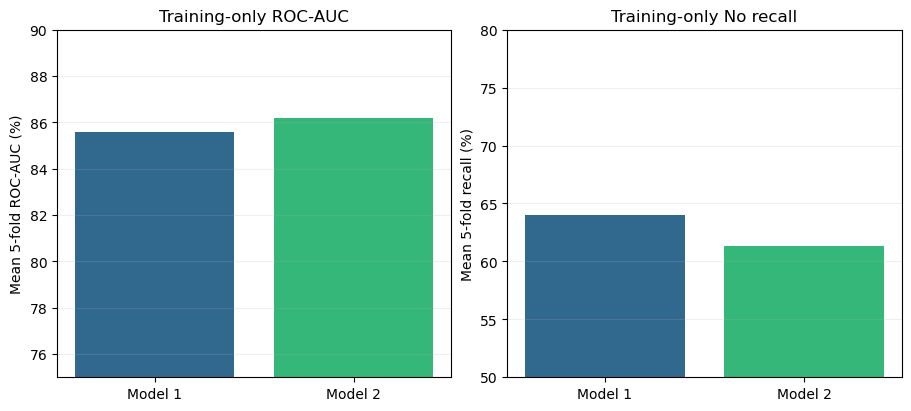

In [11]:
comparison = pd.DataFrame([
    {
        "model": "Model 1",
        "variables": 14,
        "k": 60,
        "weights": "distance",
        "distance": "Manhattan",
        "mean_CV_ROC_AUC": 0.8558,
        "mean_CV_accuracy": 0.7716,
        "mean_CV_recall_No": 0.6403,
    },
    model2_summary,
])
print(comparison.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
axes[0].bar(comparison["model"], comparison["mean_CV_ROC_AUC"] * 100, color=["#31688e", "#35b779"])
axes[0].set(title="Training-only ROC-AUC", ylabel="Mean 5-fold ROC-AUC (%)", ylim=(75, 90))
axes[1].bar(comparison["model"], comparison["mean_CV_recall_No"] * 100, color=["#31688e", "#35b779"])
axes[1].set(title="Training-only No recall", ylabel="Mean 5-fold recall (%)", ylim=(50, 80))
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
plt.show()

## Takeaway

Model 2 is a training-only experiment. Missingness is treated as information only after removing target-derived branches and free text. Do not evaluate Model 2 on the reserved test set unless its predictor set and hyperparameters are explicitly locked first.

## 7. Audit the 15 added variables

Hold Model 2's current k-NN parameters fixed (`k=60`, distance weighting, Euclidean distance). Remove each added variable one at a time and rerun the same five training folds. Define incremental contribution as:

`full Model 2 mean CV AUC − mean CV AUC without the variable`

A positive value means the variable adds predictive information conditional on the other 28 variables. This is a predictive ablation measure, not a p-value.

In [12]:
from sklearn.model_selection import cross_val_score

fixed_model2_pipeline = make_knn_pipeline(model2_features)
fixed_model2_pipeline.set_params(
    classifier__n_neighbors=60,
    classifier__weights="distance",
    classifier__p=2,
)
full_model2_scores = cross_val_score(
    fixed_model2_pipeline,
    X_model2_train,
    y_train,
    cv=validation_cv,
    scoring="roc_auc",
    n_jobs=-1,
)
full_model2_auc = full_model2_scores.mean()

ablation_rows = []
for variable in added_missing_features:
    reduced_features = [name for name in model2_features if name != variable]
    reduced_data = train_data[reduced_features].copy()
    if "i2_health" in reduced_data:
        reduced_data["i2_health"] = pd.to_numeric(reduced_data["i2_health"], errors="coerce")
    reduced_pipeline = make_knn_pipeline(reduced_features)
    reduced_pipeline.set_params(
        classifier__n_neighbors=60,
        classifier__weights="distance",
        classifier__p=2,
    )
    reduced_scores = cross_val_score(
        reduced_pipeline,
        reduced_data,
        y_train,
        cv=validation_cv,
        scoring="roc_auc",
        n_jobs=-1,
    )
    ablation_rows.append({
        "variable": variable,
        "missing_pct": cleaned_data[variable].isna().mean() * 100,
        "mean_auc_without": reduced_scores.mean(),
        "auc_loss_when_removed": full_model2_auc - reduced_scores.mean(),
    })

ablation_table = pd.DataFrame(ablation_rows).sort_values(
    "auc_loss_when_removed", ascending=False
)
print(f"Full 29-variable Model 2 mean CV AUC: {full_model2_auc:.4f}")
print(ablation_table.round(4).to_string(index=False))

Full 29-variable Model 2 mean CV AUC: 0.8619
     variable  missing_pct  mean_auc_without  auc_loss_when_removed
  had_covid_2      44.4790            0.8603                 0.0016
i12_health_10      68.3981            0.8604                 0.0015
    travel1_4      74.6345            0.8616                 0.0003
     future_1      25.3655            0.8618                 0.0002
 i12_health_9      55.9876            0.8621                -0.0002
  d1_health_5      47.0918            0.8622                -0.0003
i12_health_23      15.5677            0.8623                -0.0004
    had_covid      84.8989            0.8623                -0.0004
           w2      74.6345            0.8624                -0.0005
  d1_health_8      47.0918            0.8624                -0.0005
i12_health_24      55.9876            0.8625                -0.0006
    travel1_2      74.6345            0.8626                -0.0007
i12_health_11      15.5677            0.8631                -0.0012
 i1

## 8. Build a reduced Model 2

Use a small practical cutoff: retain an added variable when removing it lowers mean CV AUC by at least 0.0005. For overlapping pairs (`had_covid` versus `had_covid_2`, and `travel1_4` versus `travel1_2`), retain at most the stronger member according to the same ablation result. This avoids counting nearly the same construct twice in k-NN distance.

In [13]:
keep_threshold = 0.0005
kept_added = ablation_table.loc[
    ablation_table["auc_loss_when_removed"] >= keep_threshold, "variable"
].tolist()

for overlapping_pair in [
    ["had_covid", "had_covid_2"],
    ["travel1_4", "travel1_2"],
]:
    present = [name for name in overlapping_pair if name in kept_added]
    if len(present) > 1:
        stronger = (
            ablation_table[ablation_table["variable"].isin(present)]
            .sort_values("auc_loss_when_removed", ascending=False)
            .iloc[0]["variable"]
        )
        kept_added = [name for name in kept_added if name not in present or name == stronger]

reduced_model2_features = model1_features + [
    name for name in kept_added if name not in model1_features
]
print(f"Added variables retained: {len(kept_added)}")
print(kept_added)
print(f"Reduced Model 2 variables: {len(reduced_model2_features)}")

Added variables retained: 2
['had_covid_2', 'i12_health_10']
Reduced Model 2 variables: 16


In [14]:
X_reduced_model2_train = train_data[reduced_model2_features].copy()
if "i2_health" in X_reduced_model2_train:
    X_reduced_model2_train["i2_health"] = pd.to_numeric(
        X_reduced_model2_train["i2_health"], errors="coerce"
    )

reduced_model2_search = GridSearchCV(
    make_knn_pipeline(reduced_model2_features),
    model2_grid,
    scoring=scoring,
    refit="roc_auc",
    cv=validation_cv,
    n_jobs=-1,
    return_train_score=False,
)
reduced_model2_search.fit(X_reduced_model2_train, y_train)
reduced_best_index = reduced_model2_search.best_index_
reduced_model2_summary = {
    "model": "Reduced Model 2",
    "variables": len(reduced_model2_features),
    "k": reduced_model2_search.best_params_["classifier__n_neighbors"],
    "weights": reduced_model2_search.best_params_["classifier__weights"],
    "distance": "Manhattan" if reduced_model2_search.best_params_["classifier__p"] == 1 else "Euclidean",
    "mean_CV_ROC_AUC": reduced_model2_search.cv_results_["mean_test_roc_auc"][reduced_best_index],
    "mean_CV_accuracy": reduced_model2_search.cv_results_["mean_test_accuracy"][reduced_best_index],
    "mean_CV_recall_No": reduced_model2_search.cv_results_["mean_test_recall_no"][reduced_best_index],
}
final_training_comparison = pd.DataFrame([
    comparison.iloc[0].to_dict(),
    model2_summary,
    reduced_model2_summary,
])
print(final_training_comparison.round(4).to_string(index=False))

          model  variables  k  weights  distance  mean_CV_ROC_AUC  mean_CV_accuracy  mean_CV_recall_No
        Model 1         14 60 distance Manhattan           0.8558            0.7716             0.6403
        Model 2         29 60 distance Euclidean           0.8619            0.7692             0.6136
Reduced Model 2         16 80 distance Manhattan           0.8631            0.7736             0.6306


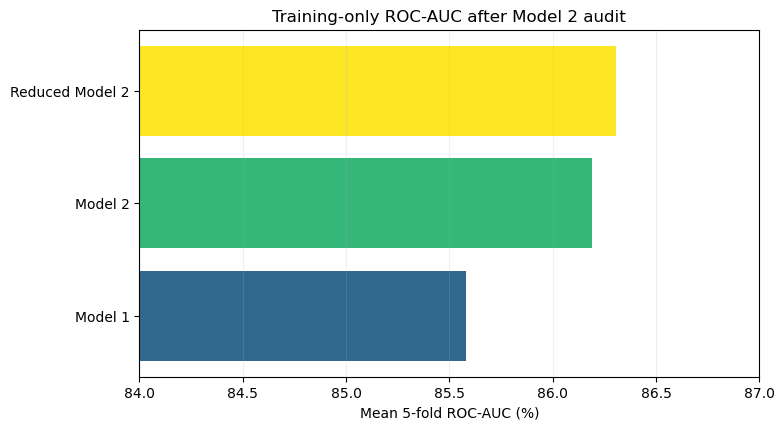

In [15]:
plot_data = final_training_comparison.sort_values("mean_CV_ROC_AUC")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(plot_data["model"], plot_data["mean_CV_ROC_AUC"] * 100, color=["#31688e", "#35b779", "#fde725"])
ax.set(title="Training-only ROC-AUC after Model 2 audit", xlabel="Mean 5-fold ROC-AUC (%)", xlim=(84, 87))
ax.grid(axis="x", alpha=0.2)
plt.show()

## Model 2 audit status

Choose between the original and reduced Model 2 using training-fold ROC-AUC, complexity, and semantic defensibility. The reserved test set remains unscored. Lock the final Model 2 specification before any test evaluation.

## 9. Final locked Model 2 test evaluation

Lock the reduced Model 2 before viewing test performance:

- 16 predictors: Model 1's 14 plus `had_covid_2` and `i12_health_10`
- `n_neighbors = 80`
- distance-weighted voting
- Manhattan distance (`p = 1`)
- primary model-selection metric: training-only 5-fold ROC-AUC

Fit on all 4,501 training rows and evaluate once on the 1,929 reserved test rows. Do not revise variables, preprocessing, threshold, or hyperparameters based on the test results.

In [16]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

assert reduced_model2_search.best_params_ == {
    "classifier__n_neighbors": 80,
    "classifier__p": 1,
    "classifier__weights": "distance",
}
locked_model2 = reduced_model2_search.best_estimator_
X_model2_test = test_data[reduced_model2_features].copy()
if "i2_health" in X_model2_test:
    X_model2_test["i2_health"] = pd.to_numeric(X_model2_test["i2_health"], errors="coerce")
y_model2_test = test_data["vac_boost_1"].eq("Yes").astype(int)
model2_test_probability = locked_model2.predict_proba(X_model2_test)[:, 1]
model2_test_prediction = locked_model2.predict(X_model2_test)

model2_test_accuracy = accuracy_score(y_model2_test, model2_test_prediction)
model2_test_auc = roc_auc_score(y_model2_test, model2_test_probability)
model2_test_confusion = confusion_matrix(
    y_model2_test, model2_test_prediction, labels=[0, 1]
)
model2_test_report = classification_report(
    y_model2_test,
    model2_test_prediction,
    labels=[0, 1],
    target_names=["No", "Yes"],
    digits=4,
    output_dict=True,
)
print(f"Locked Model 2 predictors: {len(reduced_model2_features)}")
print(f"Final test accuracy: {model2_test_accuracy:.4f}")
print(f"Final test ROC-AUC: {model2_test_auc:.4f}")
print("\nConfusion matrix (rows = actual No/Yes; columns = predicted No/Yes):")
print(model2_test_confusion)
print("\nClassification report:")
print(pd.DataFrame(model2_test_report).T.round(4).to_string())

Locked Model 2 predictors: 16
Final test accuracy: 0.7626
Final test ROC-AUC: 0.8549

Confusion matrix (rows = actual No/Yes; columns = predicted No/Yes):
[[520 315]
 [143 951]]

Classification report:
              precision  recall  f1-score    support
No               0.7843  0.6228    0.6943   835.0000
Yes              0.7512  0.8693    0.8059  1094.0000
accuracy         0.7626  0.7626    0.7626     0.7626
macro avg        0.7677  0.7460    0.7501  1929.0000
weighted avg     0.7655  0.7626    0.7576  1929.0000


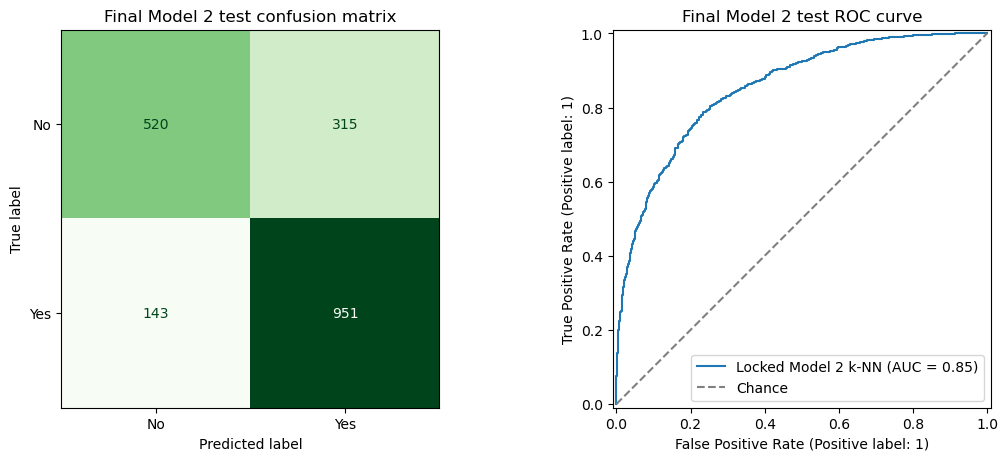

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
ConfusionMatrixDisplay(
    confusion_matrix=model2_test_confusion,
    display_labels=["No", "Yes"],
).plot(ax=axes[0], cmap="Greens", colorbar=False)
axes[0].set_title("Final Model 2 test confusion matrix")
RocCurveDisplay.from_predictions(
    y_model2_test,
    model2_test_probability,
    name="Locked Model 2 k-NN",
    ax=axes[1],
)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
axes[1].set_title("Final Model 2 test ROC curve")
axes[1].legend(loc="lower right")
plt.show()

In [18]:
final_model_comparison = pd.DataFrame([
    {
        "model": "Model 1",
        "variables": 14,
        "test_ROC_AUC": 0.8404,
        "test_accuracy": 0.7589,
        "test_precision_No": 0.7729,
        "test_recall_No": 0.6275,
        "test_F1_No": 0.6927,
        "test_precision_Yes": 0.7514,
        "test_recall_Yes": 0.8592,
        "test_F1_Yes": 0.8017,
    },
    {
        "model": "Reduced Model 2",
        "variables": len(reduced_model2_features),
        "test_ROC_AUC": model2_test_auc,
        "test_accuracy": model2_test_accuracy,
        "test_precision_No": model2_test_report["No"]["precision"],
        "test_recall_No": model2_test_report["No"]["recall"],
        "test_F1_No": model2_test_report["No"]["f1-score"],
        "test_precision_Yes": model2_test_report["Yes"]["precision"],
        "test_recall_Yes": model2_test_report["Yes"]["recall"],
        "test_F1_Yes": model2_test_report["Yes"]["f1-score"],
    },
])
print(final_model_comparison.round(4).to_string(index=False))

          model  variables  test_ROC_AUC  test_accuracy  test_precision_No  test_recall_No  test_F1_No  test_precision_Yes  test_recall_Yes  test_F1_Yes
        Model 1         14        0.8404         0.7589             0.7729          0.6275      0.6927              0.7514           0.8592       0.8017
Reduced Model 2         16        0.8549         0.7626             0.7843          0.6228      0.6943              0.7512           0.8693       0.8059


## Final evaluation rule

These are the final reserved-test results for the already locked Model 2. Do not return to variable screening, missing-value strategy selection, or hyperparameter tuning based on these results.